# Modelos de segmentación

En este capítulo describimos los seis enfoques comparados, su grado de implementación y cómo se entrenaron. Todos producen un mapa de etiquetas de instancias del tamaño de la imagen, de modo que se evalúan con el mismo código (`src/project/metrics_seg.py`). Los hiperparámetros de post-proceso de cada modelo se eligen solo en validación (`src/project/eval_seg.py`, etapa `select`), y esa elección queda congelada en `results/seg/eval/selection.pkl` antes de calcular cualquier métrica de test.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from project.book_utils import CAT, exists, need, style

style()
pd.set_option("display.precision", 3)
LABELS = {"unetpp_main": "U-Net++ + watershed", "hover_main": "Hover (NP + HV)", "maskrcnn_main": "Mask R-CNN",
          "cellpose_zeroshot": "Cellpose cero-shot", "cellpose_finetune": "Cellpose ajustado", "sam_box": "SAM (cajas)",
          "sam_auto": "SAM automático", "otsu_watershed": "Otsu + watershed"}

## Inventario y grado de implementación

| Modelo | Implementación | Origen y licencia | Objetivo de entrenamiento | Semillas |
|---|---|---|---|---|
| Otsu + *watershed* {cite:p}`otsu1979threshold,beucher1979watershed` | Propia (`seg_post.otsu_watershed`) | — | Sin aprendizaje: umbral de Otsu sobre intensidad o textura (Sobel), marcadores por distancia | determinista |
| **U-Net++ + *watershed*** {cite:p}`zhou2018unetpp` | **Propia en Keras 3** (`seg_unetpp.py`, `seg_train_keras.py`): arquitectura, pérdidas Dice, Tversky y focal, generador con *augmentation*, *watershed* por *h*-máximos | — | 3 clases (fondo, interior, borde/contacto); CE + Dice; supervisión profunda en las 4 salidas anidadas | 3 |
| Variante tipo Hover-Net {cite:p}`graham2019hovernet` | Propia en Keras sobre la misma U-Net++, con dos cabezas | — | NP: CE + Dice; HV: MSE + MSGE de los mapas horizontal y vertical | 1 (exploratorio) |
| Mask R-CNN R50-FPN v2 {cite:p}`he2017maskrcnn` | torchvision, preentrenado en COCO | BSD-3-Clause | Cajas y máscaras 28 × 28 por instancia; anclas y máximo de detecciones derivados del EDA | 3 |
| Cellpose `cyto3` {cite:p}`stringer2021cellpose,pachitariu2022cellpose2` | `cellpose` 3.1.1.3 | BSD-3-Clause | (a) cero-shot con diámetro estimado; (b) ajuste fino 100 épocas | (a) determinista; (b) 1 |
| SAM ViT-B {cite:p}`kirillov2023sam` | `segment-anything` 1.0 | Apache-2.0 | Sin ajuste: (a) generador automático; (b) *prompts* de caja de Mask R-CNN | determinista |

Mask R-CNN, Cellpose y SAM corren en PyTorch; la U-Net++ y la variante Hover, en Keras 3 con *backend* de PyTorch. Usar el mismo *backend* evita mezclar dos marcos de trabajo en la GPU, y la interfaz común es el mapa de etiquetas guardado en `results/seg/<modelo>/seed_XX/`.

## U-Net++ con *watershed*

La red tiene 5 niveles de codificación con 32, 64, 128, 256 y 512 filtros y los nodos anidados $X^{i,j}$ de U-Net++. Cada bloque son dos convoluciones 3 × 3 con normalización por lotes y ReLU. Las cuatro salidas $X^{0,1},\dots,X^{0,4}$ tienen una cabeza softmax de 3 clases y la pérdida suma las cuatro (supervisión profunda); en inferencia usamos la salida más profunda, $X^{0,4}$.

El objetivo de 3 clases convierte la separación de células en contacto en un problema de clasificación de píxeles: la clase «borde» cubre 2 píxeles hacia dentro del contorno de cada célula, incluidas las zonas de contacto. El *watershed* inunda $-P(\text{interior})$ suavizada desde los *h*-máximos de esa misma probabilidad, restringido al primer plano $P(\text{interior}) + P(\text{borde}) > t$. La rejilla de post-proceso tiene 18 combinaciones: $t \in \{0.4, 0.5, 0.6\}$, $h \in \{0.05, 0.1, 0.2\}$ y tamaño mínimo $\in \{15, 30\}$ píxeles.

Entrenamos con AdamW (tasa 10⁻³, decaimiento 10⁻⁴), 2 épocas de calentamiento y decaimiento coseno, recortes de 256 × 256, lotes de 8, 100 pasos por época, hasta 35 épocas y paciencia 8 sobre la pérdida de validación, con precisión mixta.

In [2]:
runs = []
for model in LABELS:
    for s in range(3):
        p = f"seg/{model}/seed_{s:02d}"
        if exists(f"{p}/timing.pkl"):
            t = need(f"{p}/timing.pkl")
            runs.append(dict(modelo=LABELS[model], semilla=s, parámetros=t.get("params"), épocas=t.get("epochs_run"),
                             mejor_época=t.get("best_epoch"), s_por_época=t.get("sec_per_epoch"),
                             s_inferencia_por_imagen=t.get("infer_sec_per_image", t.get("infer_sec_per_image_grid")),
                             VRAM_pico_GB=t.get("peak_vram_gb")))
runs = pd.DataFrame(runs)
runs

,modelo,semilla,parámetros,épocas,mejor_época,s_por_época,s_inferencia_por_imagen,VRAM_pico_GB
0,U-Net++ + watershed,0,9.053e+06,35.0,27.0,79.662,0.106,8.764
1,U-Net++ + watershed,1,9.053e+06,35.0,31.0,53.319,0.099,9.027
2,U-Net++ + watershed,2,9.053e+06,35.0,31.0,52.962,0.099,9.647
3,Hover (NP + HV),0,9.053e+06,35.0,27.0,70.588,0.122,9.093
4,Mask R-CNN,0,4.588e+07,24.0,19.0,174.156,2.670,10.094
5,Mask R-CNN,1,4.588e+07,23.0,17.0,184.074,2.532,10.314
6,Mask R-CNN,2,4.588e+07,17.0,11.0,155.509,2.412,10.010
7,Cellpose cero-shot,0,NaN,NaN,NaN,NaN,5.255,NaN
8,Cellpose ajustado,0,NaN,NaN,NaN,NaN,3.452,NaN
9,SAM (cajas),0,NaN,NaN,NaN,NaN,0.977,NaN


Las tres semillas de la U-Net++ llegaron al máximo de 35 épocas sin activar la parada temprana. La primera semilla tardó más por época porque coincidió con trabajos de CPU en paralelo (bitácora, 07:40); las otras dos tardaron unos 53 s por época. Los tiempos de inferencia de los modelos de Cellpose y SAM incluyen toda la rejilla de post-proceso o la generación de máscaras, y no son comparables uno a uno con los de las redes; la comparación de latencia controlada está en el capítulo {doc}`14_seg_ablaciones_robustez`.

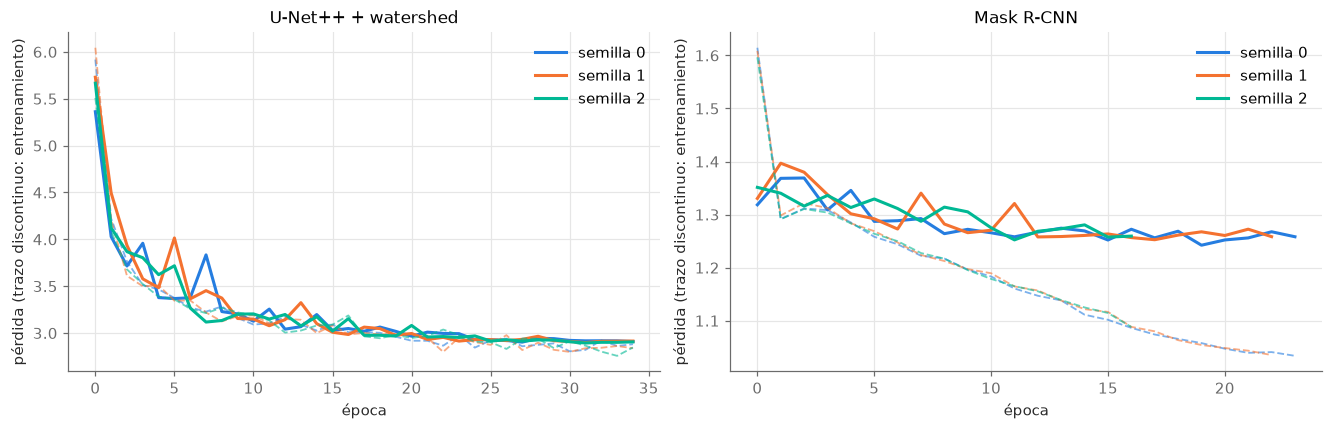

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for k, (model, ax) in enumerate(zip(["unetpp_main", "maskrcnn_main"], axes)):
    for s in range(3):
        p = f"seg/{model}/seed_{s:02d}/history.pkl"
        if exists(p):
            h = pd.DataFrame(need(p))
            ax.plot(h.epoch, h.loss, color=CAT[s], lw=1.2, alpha=0.6, ls="--")
            ax.plot(h.epoch, h.val_loss, color=CAT[s], lw=2, label=f"semilla {s}")
    ax.set(title=LABELS[model], xlabel="época", ylabel="pérdida (trazo discontinuo: entrenamiento)")
    ax.legend()
plt.show()

Las curvas muestran la pérdida de entrenamiento (discontinua) y la de validación (continua) por semilla. En las dos redes la pérdida de validación sigue a la de entrenamiento sin separarse de forma sostenida, así que el límite de épocas, y no el sobreajuste, es lo que corta el entrenamiento. La pérdida de Mask R-CNN es la suma de sus cinco términos (clasificación y regresión del RPN, clasificación y regresión de cajas, máscara) y no es comparable en escala con la de la U-Net++.

## Mask R-CNN

Partimos de `maskrcnn_resnet50_fpn_v2` con pesos de COCO. Reemplazamos el generador de anclas por tamaños de 12, 24, 48, 96 y 192 píxeles con razones de aspecto 0.5, 1 y 2, que cubren el rango de lados de caja del EDA (8.5 a 89 píxeles entre los percentiles 1 y 99), y permitimos hasta 1000 detecciones por imagen, por encima del máximo de 790 células anotadas en una imagen. Las cabezas de caja y de máscara se reinician para dos clases (fondo y célula). Entrenamos con SGD (momento 0.9, tasa 0.01, calentamiento de 200 iteraciones y coseno), lotes de 2 imágenes completas, volteos y ajuste de brillo y contraste, precisión mixta, hasta 24 épocas y paciencia 5.

El post-proceso convierte las máscaras en un mapa de etiquetas: ordena las instancias por puntuación, binariza cada máscara con un umbral y asigna cada píxel a la instancia de mayor puntuación que lo cubre. En validación elegimos el umbral de puntuación y el de máscara.

## Variante tipo Hover-Net

Usamos la misma U-Net++ con dos cabezas: NP (probabilidad de célula) y HV (distancia horizontal y vertical normalizada al centroide de cada célula, en $[-1, 1]$). El post-proceso sigue a HoVer-Net: los gradientes de los mapas HV son grandes en los límites entre células, y restarlos a la probabilidad NP da los marcadores del *watershed*. No es la implementación oficial: no tiene la rama de clasificación de núcleos ni el *backbone* preactivado de HoVer-Net, y la rotulamos como variante.

## Cellpose

El modelo generalista `cyto3` predice campos de flujo hacia el centro de cada célula y una probabilidad de célula. En el modo cero-shot estimamos el diámetro de cada imagen con el estimador de Cellpose; en el modo ajustado entrenamos 100 épocas sobre las imágenes de entrenamiento (tasa 0.005, lotes de 8) y usamos el diámetro medio de las células de entrenamiento que calcula Cellpose al ajustar (`diam_labels`). En validación elegimos el umbral de probabilidad de célula (−1, 0 o 1) y el de error de flujo (0.4 o 0.6).

## SAM

Usamos SAM ViT-B sin ajuste. En el modo automático, el generador recorre una rejilla de 48 × 48 puntos; descartamos las máscaras que ocupan más del 2 % de la imagen (fondo o grupos de células) y en validación elegimos el umbral de IoU predicho (0.70, 0.80 o 0.88) y el de estabilidad (0.8 o 0.9). En el modo con cajas, SAM recibe como *prompt* cada caja detectada por Mask R-CNN (semilla 0) y devuelve una máscara por caja; en validación elegimos el umbral de puntuación de la caja (0.3 a 0.7). Este modo mide si SAM mejora las máscaras de un detector entrenado en el dominio.

## Selección del post-proceso en validación

La tabla muestra la configuración elegida para cada modelo y el AP medio de validación con esa configuración, promediado entre las semillas disponibles. Esta es la única información de rendimiento que usamos para decidir; las métricas de test están en el capítulo siguiente.

In [4]:
sel = need("seg/eval/selection.pkl")
tab = pd.DataFrame([dict(modelo=LABELS.get(m, m), configuración=v["config"], AP_val=v["val_ap"], semillas=len(v["seeds"]),
                         configuraciones_probadas=len(v["grid"]),
                         rango_AP_rejilla=v["grid"].max() - v["grid"].min()) for m, v in sel.items() if m in LABELS])
tab.sort_values("AP_val", ascending=False)

,modelo,configuración,AP_val,semillas,configuraciones_probadas,rango_AP_rejilla
2,Cellpose ajustado,cp+0_f0.4,0.264,1,6,0.062
5,Mask R-CNN,s0.4_m0.6,0.245,3,15,0.031
1,U-Net++ + watershed,t0.60_h0.20_m30,0.226,3,18,0.013
7,SAM (cajas),s0.4,0.199,1,5,0.011
4,Hover (NP + HV),t0.60_k0.50_m30,0.109,1,18,0.077
3,Cellpose cero-shot,cp+0_f0.4,0.096,1,6,0.026
6,SAM automático,p0.80_s0.90,0.025,1,6,0.006
0,Otsu + watershed,texture_s1_d8_m30,0.009,1,24,0.009


El rango de AP dentro de la rejilla mide cuánto depende cada modelo de su post-proceso. Un rango grande significa que una mala elección de umbrales puede cambiar el orden entre modelos, y justifica haber elegido el post-proceso de todos los modelos con la misma regla y el mismo conjunto de validación.

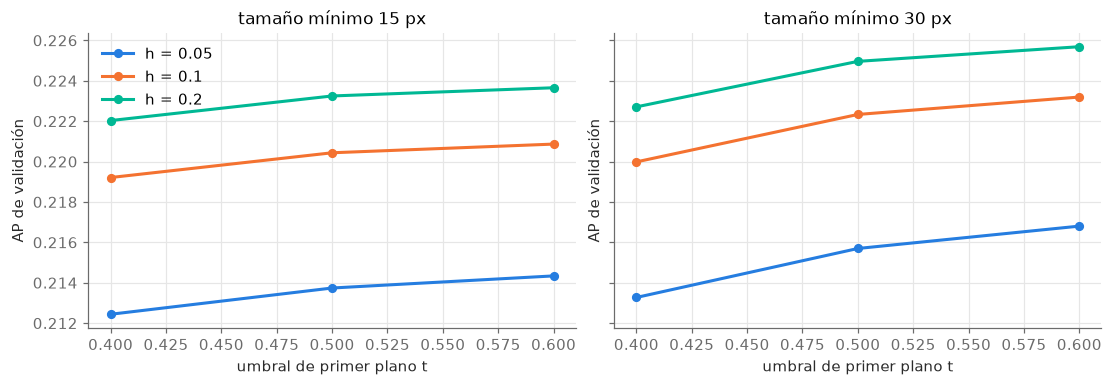

In [5]:
if "unetpp_main" in sel:
    g = sel["unetpp_main"]["grid"]
    G = pd.DataFrame([dict(zip(["t_fg", "h", "min_size"], [float(c.split("_")[0][1:]), float(c.split("_")[1][1:]),
                                                         int(c.split("_")[2][1:])]), AP=v) for c, v in g.items()])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
    for ax, ms in zip(axes, (15, 30)):
        for k, h in enumerate((0.05, 0.1, 0.2)):
            d = G[(G.min_size == ms) & (G.h == h)].sort_values("t_fg")
            ax.plot(d.t_fg, d.AP, "o-", color=CAT[k], label=f"h = {h}", ms=5)
        ax.set(title=f"tamaño mínimo {ms} px", xlabel="umbral de primer plano t", ylabel="AP de validación")
    axes[0].legend()
    plt.show()